# 1. Setup

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from transformers import AutoModelForImageClassification

CLASSES = ["call", "dislike", "fist", "four", "like"]
PROB_COLS = [f"prob_{c}" for c in CLASSES]


files = {
    "original": "/Users/Jakub/Desktop/AI-VIS/phase1-Ai/split_preprocess-train/base results and setup/test_set_merged.csv",
    "flipped_upside_down": "/Users/Jakub/Downloads/test_results_flipped_upside_down.csv",
    "black_and_white": "/Users/Jakub/Downloads/test_results_black_and_white.csv",
    "brightness_raised": "/Users/Jakub/Downloads/test_results_brightness_raised.csv",
    "flipped_90": "/Users/Jakub/Downloads/test_results_flipped_90.csv",
    "flipped_horizontal": "/Users/Jakub/Downloads/test_results_flipped_horizontal.csv",
}

data = {name: pd.read_csv(path) for name, path in files.items()}
for name, d in data.items():
    print(name, "accuracy:", d["correct"].mean())

original accuracy: 0.871
flipped_upside_down accuracy: 0.257
black_and_white accuracy: 0.734
brightness_raised accuracy: 0.714
flipped_90 accuracy: 0.295
flipped_horizontal accuracy: 0.251


# 2. Predicted class distribution, orientation transforms vs original

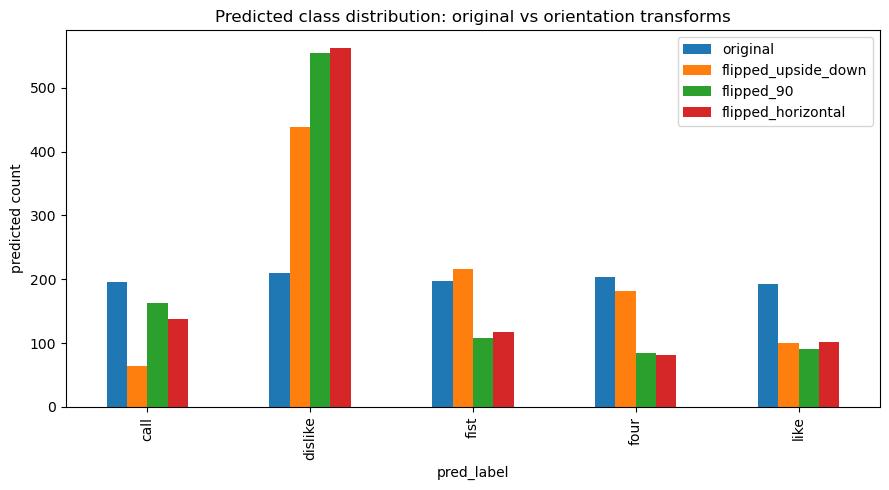

In [3]:
orientation = ["original", "flipped_upside_down", "flipped_90", "flipped_horizontal"]

counts = pd.DataFrame({
    name: data[name]["pred_label"].value_counts().reindex(CLASSES).fillna(0)
    for name in orientation
})

ax = counts.plot(kind="bar", figsize=(9, 5))
ax.set_ylabel("predicted count")
ax.set_title("Predicted class distribution: original vs orientation transforms")
plt.tight_layout()
plt.show()

# 3. Mean assigned probability per class, original vs each transform

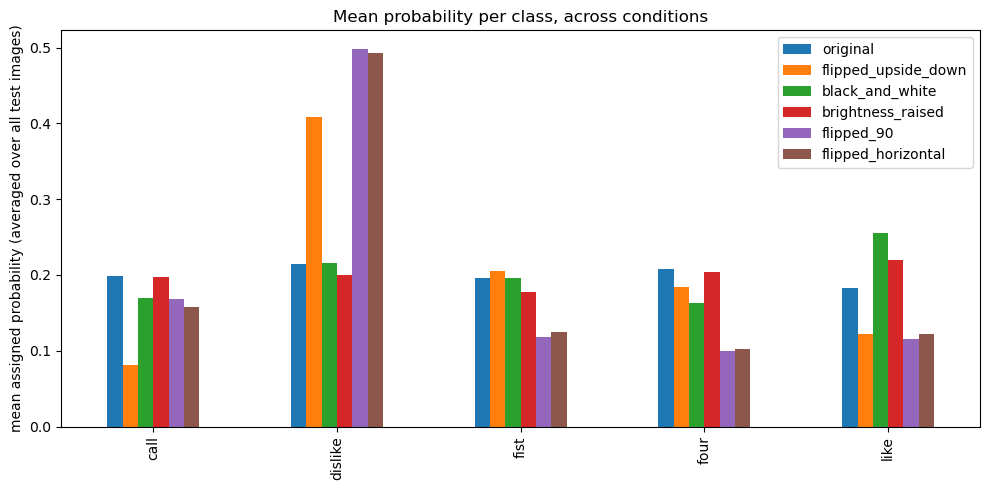

         original  flipped_upside_down  black_and_white  brightness_raised  \
call     0.198625             0.081168         0.169399           0.197128   
dislike  0.214835             0.408423         0.215319           0.200584   
fist     0.195683             0.204710         0.196114           0.177521   
four     0.207420             0.183941         0.163468           0.204594   
like     0.183438             0.121759         0.255700           0.220174   

         flipped_90  flipped_horizontal  
call       0.168398            0.157887  
dislike    0.498005            0.493170  
fist       0.118361            0.124137  
four       0.099391            0.102715  
like       0.115846            0.122091  


In [4]:
mean_probs = pd.DataFrame({
    name: data[name][PROB_COLS].mean().values
    for name in files
}, index=CLASSES)

ax = mean_probs.plot(kind="bar", figsize=(10, 5))
ax.set_ylabel("mean assigned probability (averaged over all test images)")
ax.set_title("Mean probability per class, across conditions")
plt.tight_layout()
plt.show()

print(mean_probs)

# 4. Classifier bias terms (direct mechanistic check: is 'dislike' the model's default output?)

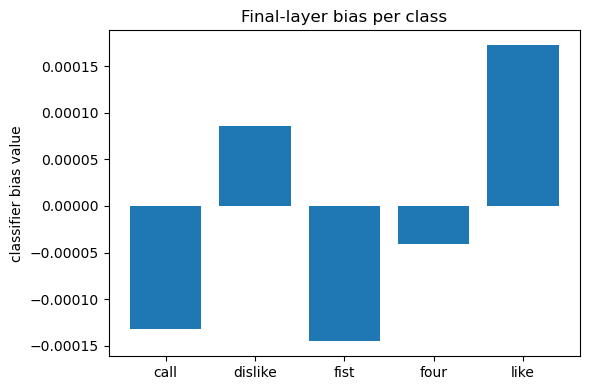

{'call': -0.00013251978, 'dislike': 8.565138e-05, 'fist': -0.00014548877, 'four': -4.039318e-05, 'like': 0.00017264174}


In [6]:
MODEL_PATH = "/Users/Jakub/Desktop/AI-VIS/phase1-Ai/split_preprocess-train/model"
model = AutoModelForImageClassification.from_pretrained(MODEL_PATH)
bias = model.classifier.bias.detach().numpy()

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(CLASSES, bias)
ax.set_ylabel("classifier bias value")
ax.set_title("Final-layer bias per class")
plt.tight_layout()
plt.show()

print(dict(zip(CLASSES, bias)))

# 5. P(dislike) by true label, for each orientation transform (uniform collapse vs class-dependent)

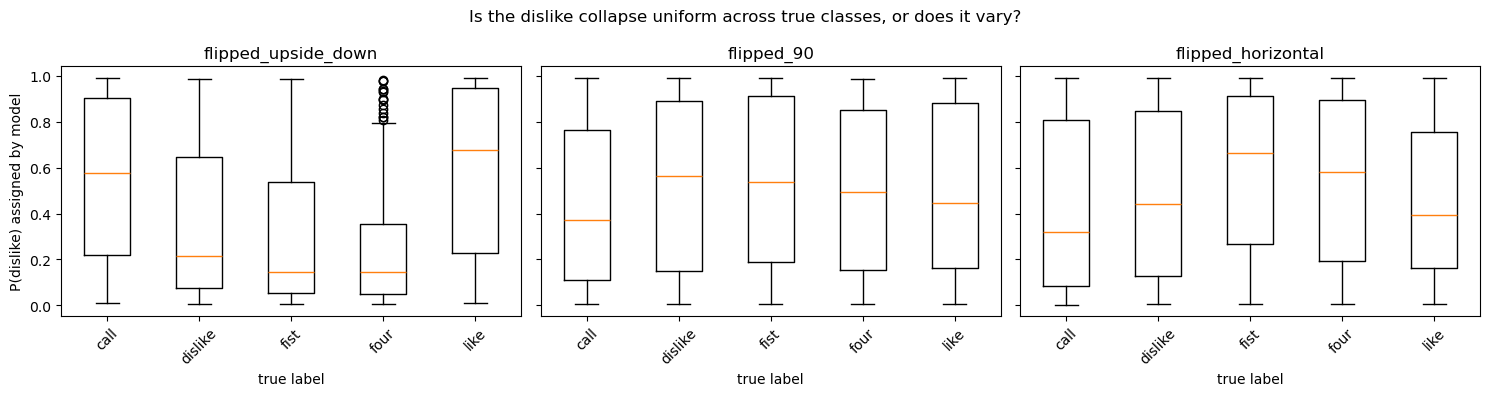

In [7]:
fig, axes = plt.subplots(1, len(orientation) - 1, figsize=(15, 4), sharey=True)
for ax, name in zip(axes, orientation[1:]):
    d = data[name]
    groups = [d.loc[d["true_label"] == c, "prob_dislike"] for c in CLASSES]
    ax.boxplot(groups, tick_labels=CLASSES)
    ax.set_title(name)
    ax.set_xlabel("true label")
    ax.tick_params(axis="x", rotation=45)
axes[0].set_ylabel("P(dislike) assigned by model")
plt.suptitle("Is the dislike collapse uniform across true classes, or does it vary?")
plt.tight_layout()
plt.show()

# 6. Thumbnail grid: flipped images predicted as dislike, by true label (visual check)

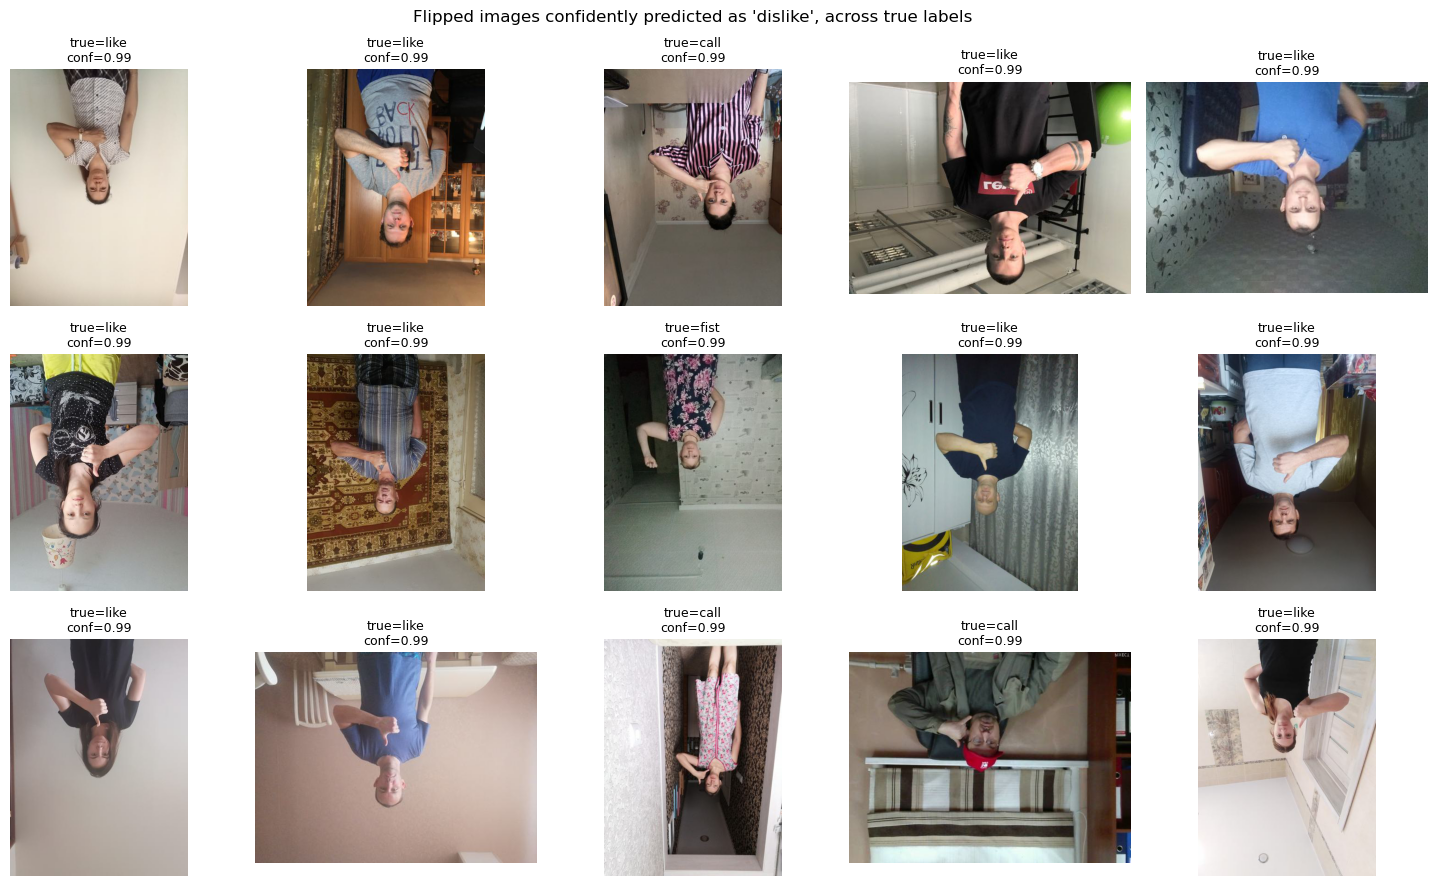

In [9]:
import os
import glob
from PIL import Image

DATA_ROOT = "/Users/Jakub/Desktop/School/VISAI/hagrid-sample-30k-384p/hagrid_30k"

def find_path(img_id, label):
    pattern = os.path.join(DATA_ROOT, f"train_val_{label}", f"{img_id}.*")
    matches = glob.glob(pattern)
    return matches[0] if matches else None

d = data["flipped_upside_down"]
sample = d[d["pred_label"] == "dislike"].sort_values("confidence", ascending=False)

fig, axes = plt.subplots(3, 5, figsize=(15, 9))
for ax, (_, row) in zip(axes.flat, sample.iterrows()):
    path = find_path(row["id"], row["true_label"])
    if path:
        img = Image.open(path).convert("RGB").transpose(Image.FLIP_TOP_BOTTOM)
        ax.imshow(img)
    ax.set_title(f"true={row['true_label']}\nconf={row['confidence']:.2f}", fontsize=9)
    ax.axis("off")
plt.suptitle("Flipped images confidently predicted as 'dislike', across true labels")
plt.tight_layout()
plt.show()

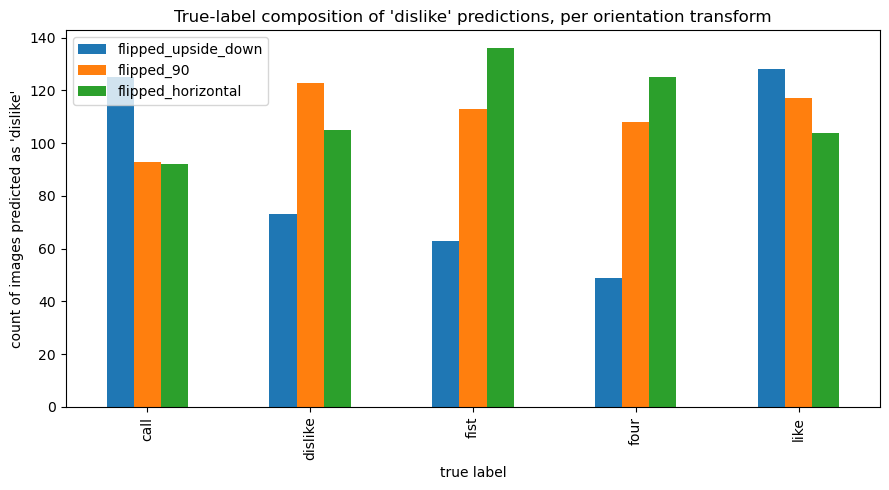

In [10]:
orientation_transforms = ["flipped_upside_down", "flipped_90", "flipped_horizontal"]
CLASSES = ["call", "dislike", "fist", "four", "like"]

composition = pd.DataFrame({
    name: data[name][data[name]["pred_label"] == "dislike"]["true_label"]
          .value_counts().reindex(CLASSES).fillna(0)
    for name in orientation_transforms
})

ax = composition.plot(kind="bar", figsize=(9, 5))
ax.set_ylabel("count of images predicted as 'dislike'")
ax.set_xlabel("true label")
ax.set_title("True-label composition of 'dislike' predictions, per orientation transform")
plt.tight_layout()
plt.show()